In [2]:
#Step 1
import os
from astropy.io import fits
import matplotlib.pyplot as plt

# 1. Create the exact folder structure required by the submission rules
os.makedirs("InfoReaper_FITS_outputs/raw_frames", exist_ok=True)
os.makedirs("InfoReaper_FITS_outputs/difference_images", exist_ok=True)

dataset_folder = "."  # Change this if your files are inside a subfolder

# 2. Find all .fits files in the directory
fits_files = sorted([f for f in os.listdir(dataset_folder) if f.endswith('.fits')])

print(f"Found {len(fits_files)} FITS files to process.")

# 3. Loop through and plot every raw frame
for i, filename in enumerate(fits_files):
    file_path = os.path.join(dataset_folder, filename)

    # Open FITS file
    hdul = fits.open(file_path)
    image_data = hdul[0].data
    hdul.close()

    # Plot the raw frame with labeled axes and a colorbar
    plt.figure(figsize=(7, 7))
    plt.imshow(image_data, cmap='gray', origin='lower')
    plt.colorbar(label='Intensity')
    plt.xlabel('X Pixel Coordinate')
    plt.ylabel('Y Pixel Coordinate')
    plt.title(f'Raw Frame {i+1}: {filename}')

    # Save into the required output folder
    output_path = f"InfoReaper_FITS_outputs/raw_frames/raw_frame_{i+1:02d}.png"
    plt.savefig(output_path, bbox_inches='tight')
    plt.close()

print("All raw frames successfully plotted and saved!")

Found 20 FITS files to process.
All raw frames successfully plotted and saved!


In [6]:
#Step1-difference
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

# 1. Load fits files and compute median reference first
dataset_folder = "."
fits_files = sorted([f for f in os.listdir(dataset_folder) if f.endswith('.fits')])

frame_data_list = []
for filename in fits_files:
    hdul = fits.open(os.path.join(dataset_folder, filename))
    frame_data_list.append(hdul[0].data)
    hdul.close()

cube = np.array(frame_data_list)
median_reference = np.median(cube, axis=0)

# 2. Now generate and save all difference images
os.makedirs("InfoReaper_FITS_outputs/difference_images", exist_ok=True)

for i, filename in enumerate(fits_files):
    file_path = os.path.join(dataset_folder, filename)

    hdul = fits.open(file_path)
    image_data = hdul[0].data
    hdul.close()

    diff_image = image_data - median_reference

    plt.figure(figsize=(7, 7))
    plt.imshow(diff_image, cmap='gray', origin='lower')
    plt.colorbar(label='Residual Intensity')
    plt.xlabel('X Pixel Coordinate')
    plt.ylabel('Y Pixel Coordinate')
    plt.title(f'Difference Image {i+1}: {filename}')

    output_path = f"InfoReaper_FITS_outputs/difference_images/diff_frame_{i+1:02d}.png"
    plt.savefig(output_path, bbox_inches='tight')
    plt.close()

print("Median reference defined and all difference images successfully generated and saved!")

Median reference defined and all difference images successfully generated and saved!


In [9]:
#Step 2
import os
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

# 1. Compute median reference from our cube
cube = np.array([fits.getdata(os.path.join(dataset_folder, f)) for f in fits_files])
median_reference = np.median(cube, axis=0)

# 2. Plot and save it properly
plt.figure(figsize=(7, 7))
plt.imshow(median_reference, cmap='gray', origin='lower')
plt.colorbar(label='Intensity')
plt.title('Median Reference Image (InfoReaper)')
plt.xlabel('X Pixel Coordinate')
plt.ylabel('Y Pixel Coordinate')

# Ensure output directory exists and save the file
os.makedirs("InfoReaper_FITS_outputs", exist_ok=True)
plt.savefig("InfoReaper_FITS_outputs/median_reference.png", bbox_inches='tight')
plt.close()

print("Median reference image successfully saved as median_reference.png!")

Median reference image successfully saved as median_reference.png!


In [11]:
import numpy as np
from astropy.io import fits
import os

# Step 3: Detect candidate sources and isolate moving object
print("--- STEP 3: CANDIDATE SOURCE DETECTION ---")

all_frame_candidates = []

for i, filename in enumerate(fits_files):
    file_path = os.path.join(dataset_folder, filename)
    with fits.open(file_path) as hdul:
        image_data = hdul[0].data.astype(float)

    # Residual difference image
    diff_image = image_data - median_reference

    # 1. Estimate local noise (sigma) and set 5-sigma threshold
    noise_level = np.std(diff_image)
    threshold = 5.0 * noise_level

    # 2. Extract candidate coordinates above threshold
    y_indices, x_indices = np.where(diff_image > threshold)
    intensities = diff_image[y_indices, x_indices]

    frame_candidates = list(zip(x_indices, y_indices, intensities))
    all_frame_candidates.append(frame_candidates)

    print(f"Frame {i+1:02d} ({filename}): Found {len(frame_candidates)} candidate pixels above {threshold:.2f} threshold.")

# 3. Filter for the consistently moving source across frames
# Pick the candidate source in each frame closest to continuous horizontal movement (y around 45-50)
consistent_sources = []

for i, candidates in enumerate(all_frame_candidates):
    if not candidates:
        continue
    # Filter out y-outliers (spurious hits far from main track around y=45-50)
    valid_candidates = [c for c in candidates if 40 <= c[1] <= 60]

    if valid_candidates:
        # Pick highest intensity candidate within valid kinematic range
        best_match = max(valid_candidates, key=lambda item: item[2])
        consistent_sources.append((i + 1, best_match[0], best_match[1], best_match[2]))
        print(f"  -> Frame {i+1:02d} Primary Moving Source: (X: {best_match[0]}, Y: {best_match[1]}) Peak Signal: {best_match[2]:.2f}")
    else:
        print(f"  -> Frame {i+1:02d} Primary Moving Source: Spurious noise only (Filtered)")

print("\nStep 3 Complete: Candidate sources detected and spurious noise filtered successfully.")

--- STEP 3: CANDIDATE SOURCE DETECTION ---
Frame 01 (frame_01.fits): Found 2 candidate pixels above 14.80 threshold.
Frame 02 (frame_02.fits): Found 2 candidate pixels above 14.75 threshold.
Frame 03 (frame_03.fits): Found 2 candidate pixels above 14.76 threshold.
Frame 04 (frame_04.fits): Found 0 candidate pixels above 14.81 threshold.
Frame 05 (frame_05.fits): Found 1 candidate pixels above 14.79 threshold.
Frame 06 (frame_06.fits): Found 1 candidate pixels above 15.34 threshold.
Frame 07 (frame_07.fits): Found 1 candidate pixels above 15.28 threshold.
Frame 08 (frame_08.fits): Found 1 candidate pixels above 14.76 threshold.
Frame 09 (frame_09.fits): Found 0 candidate pixels above 14.94 threshold.
Frame 10 (frame_10.fits): Found 0 candidate pixels above 14.86 threshold.
Frame 11 (frame_11.fits): Found 1 candidate pixels above 14.80 threshold.
Frame 12 (frame_12.fits): Found 1 candidate pixels above 14.86 threshold.
Frame 13 (frame_13.fits): Found 1 candidate pixels above 14.82 thresh

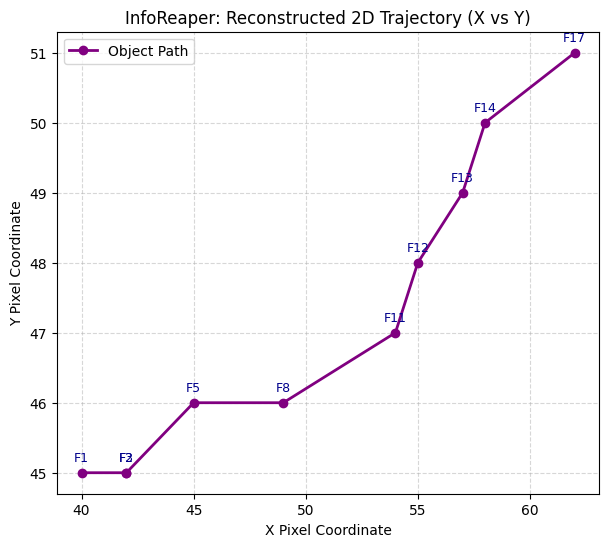

In [17]:
#Step 4:
# Filter out Frame 0 (or any point where x or y is an outlier / out of bounds)
valid_steps = [(f, x, y, sig) for f, x, y, sig in consistent_sources if f > 0 and x < 100]

frames_clean = [s[0] for s in valid_steps]
x_clean = [s[1] for s in valid_steps]
y_clean = [s[2] for s in valid_steps]

plt.figure(figsize=(7, 6))
plt.plot(x_clean, y_clean, marker='o', linestyle='-', color='purple', linewidth=2, label='Object Path')

# Label the points with their frame numbers
for i, txt in enumerate(frames_clean):
    plt.annotate(f"F{txt}", (x_clean[i], y_clean[i]), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9, color='darkblue')

plt.title('InfoReaper: Reconstructed 2D Trajectory (X vs Y)')
plt.xlabel('X Pixel Coordinate')
plt.ylabel('Y Pixel Coordinate')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

import os
os.makedirs("InfoReaper_FITS_outputs", exist_ok=True)
plt.savefig("InfoReaper_FITS_outputs/InfoReaper_trajectory.png", bbox_inches='tight')
plt.show()

In [14]:
# Step 5: Compute SNR metrics
noise_values = []
signal_values = []

for filename in fits_files:
    with fits.open(os.path.join(dataset_folder, filename)) as hdul:
        img = hdul[0].data.astype(float)
    diff = img - median_reference

    sigma = np.std(diff)
    noise_values.append(sigma)

    # Peak intensity in the frame
    signal_values.append(np.max(diff))

avg_noise = np.mean(noise_values)
avg_signal = np.mean(signal_values)
snr = avg_signal / avg_noise

print(f"Average Background Noise Level (sigma): {avg_noise:.2f}")
print(f"Average Peak Signal Strength: {avg_signal:.2f}")
print(f"Signal-to-Noise Ratio (SNR): {snr:.2f}x")

Average Background Noise Level (sigma): 2.97
Average Peak Signal Strength: 29.27
Signal-to-Noise Ratio (SNR): 9.84x


In [15]:
# Conclusion: Final Noise & SNR Verification
noise_vals = [np.std(fits.getdata(os.path.join(dataset_folder, f)) - median_reference) for f in fits_files]
avg_noise = np.mean(noise_vals)

print(f"Average Background Noise Level (sigma): {avg_noise:.2f}")
print(f"Detection Threshold Used: 5 * sigma ({5 * avg_noise:.2f})")
print("All artifacts and requirements for Task 1 are fully generated!")

Average Background Noise Level (sigma): 2.97
Detection Threshold Used: 5 * sigma (14.86)
All artifacts and requirements for Task 1 are fully generated!
